# Extended Data Fig. 6

Redraws all panels of Extended Data Fig. 6 from the figshare source data: `Wilhelm_SourceData_ED_Fig6a.parquet`,
`Wilhelm_SourceData_ED_Fig6b.parquet` and `Wilhelm_SourceData_ED_Fig6c.parquet` (spectral angle of each spectrum and
model) with the n and median tables `Wilhelm_SourceData_ED_Fig6{a,b,c}_summary.csv`.

All panels are split violins (`split=True`, seaborn violinplot defaults otherwise: Scott bandwidth (scaled by
`bw_adjust=2.5` in panel c), `cut=2`, area scaling); of the `inner='quart'` lines only the median is drawn (dashed).

Data access: files are downloaded from the figshare article given by `FIGSHARE_ARTICLE_ID` (config cell below or environment variable; set `FIGSHARE_TOKEN` while the article is private) into `./data`, or read from a local copy of the deposit if the environment variable `SOURCE_DATA_DIR` points to it. Panels are saved to `regenerated_panels/ED_Fig6/` (PDF and PNG).

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'ED_Fig6'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(name):
    for ext in ('pdf', 'png'):
        plt.savefig(FIG_DIR / f'{name}.{ext}', dpi=300, bbox_inches='tight')


def median_only(ax, data, x, y, hue, order, hue_order):
    """Keep only the median line of inner='quart' (dashed) and remove the quartile lines."""
    med = data.groupby([x, hue])[y].median()
    for line in list(ax.lines):
        xs, ys = line.get_xdata(), line.get_ydata()
        if len(ys) != 2 or ys[0] != ys[1]:
            continue
        xm = float(np.mean(xs))
        gi = int(round(xm))
        if not 0 <= gi < len(order):
            continue
        h = hue_order[0] if xm < gi else hue_order[1]
        m = med.get((order[gi], h), np.nan)
        if np.isclose(ys[0], m, atol=1e-9):
            line.set_linestyle((0, (4, 2)))
            line.set_linewidth(1.2)
        else:
            line.remove()


pd.set_option('display.max_colwidth', 200)
readme('ED_Fig6')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Extended Data Fig. 6,a,NaN,Wilhelm_SourceData_ED_Fig6a.parquet; Wilhelm_SourceData_ED_Fig6a_summary.csv,"Spectral angle of each spectrum, Prosit-40PTM and the published Prosit models (Koina names); n and medians in Wilhelm_SourceData_ED_Fig6a_summary.csv.",NaN
1,Extended Data Fig. 6,b,NaN,Wilhelm_SourceData_ED_Fig6b.parquet; Wilhelm_SourceData_ED_Fig6b_summary.csv,"Spectral angle of each HCD spectrum per seen-PTM group, Prosit-40PTM and Prosit-22PTM; n labels and medians in Wilhelm_SourceData_ED_Fig6b_summary.csv.",NaN
2,Extended Data Fig. 6,c,NaN,Wilhelm_SourceData_ED_Fig6c.parquet; Wilhelm_SourceData_ED_Fig6c_summary.csv,"Spectral angle of each HCD spectrum per PTM unseen by Prosit-22PTM, Prosit-40PTM and Prosit-22PTM on the same spectra; n and medians in Wilhelm_SourceData_ED_Fig6c_summary.csv.",NaN


## Panel a — Prosit-40PTM vs published Prosit models
Spectral angle of Prosit-40PTM (left half) and the corresponding published Prosit model (right half, Koina name) per data
set. Each model is shown on the spectra of its own prediction file; the published TMT model file contains one spectrum per
precursor (`published_model_file_one_spectrum_per_precursor`). n labels: Prosit-40PTM / published model spectra.

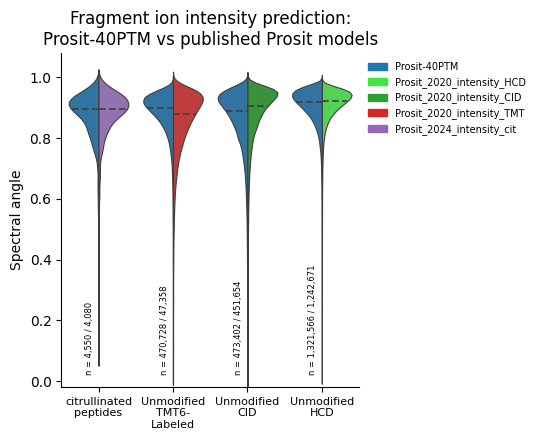

,comparison,published_model (Koina name),fragmentation,n_spectra_Prosit-40PTM,n_spectra_published_model,median_SA_Prosit-40PTM,median_SA_published_model,published_model_file_one_spectrum_per_precursor
0,citrullinated peptides,Prosit_2024_intensity_cit,HCD,4550,4080,0.894524,0.897049,False
1,Unmodified TMT-6 Labeled,Prosit_2020_intensity_TMT,HCD,470728,47358,0.899472,0.881084,True
2,Unmodified CID,Prosit_2020_intensity_CID,CID,473402,451654,0.887755,0.906112,False
3,Unmodified HCD,Prosit_2020_intensity_HCD,HCD,1321566,1242671,0.917757,0.922214,False


In [3]:
a_sum = table('ED_Fig6a_summary')
a = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig6a.parquet'))
order = a_sum['comparison'].tolist()
PUB_COL = {'Prosit_2020_intensity_HCD': '#3ee83e', 'Prosit_2020_intensity_CID': '#2ca02c',
           'Prosit_2020_intensity_TMT': '#d62728', 'Prosit_2024_intensity_cit': '#9467bd'}
BLUE = '#1f77b4'
a['side'] = np.where(a['model'] == 'Prosit-40PTM', 'Prosit-40PTM', 'published')
long = a[['comparison', 'side', 'spectral_angle']].rename(columns={'side': 'model'})
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for comp, pub in zip(a_sum['comparison'], a_sum['published_model (Koina name)']):
    sns.violinplot(data=long[long['comparison'] == comp], x='comparison', y='spectral_angle', hue='model',
                   order=order, hue_order=['Prosit-40PTM', 'published'], split=True, inner='quart',
                   palette={'Prosit-40PTM': BLUE, 'published': PUB_COL[pub]}, linewidth=0.8, ax=ax, legend=False)
median_only(ax, long, 'comparison', 'spectral_angle', 'model', order, ['Prosit-40PTM', 'published'])
for i, r in a_sum.iterrows():
    ax.text(i - 0.12, 0.02, 'n = {:,} / {:,}'.format(r['n_spectra_Prosit-40PTM'],
            r['n_spectra_published_model']), rotation=90, fontsize=6, ha='center', va='bottom')
ax.set_xticks(range(len(order)), [o.replace(' peptides', '\npeptides').replace('TMT-6 ', 'TMT6-\n')
                                  .replace('Unmodified ', 'Unmodified\n') for o in order], fontsize=8)
ax.set_xlabel('')
ax.set_ylabel('Spectral angle')
ax.set_ylim(-0.02, 1.08)
ax.set_title('Fragment ion intensity prediction:\nProsit-40PTM vs published Prosit models')
ax.legend([Patch(color=BLUE)] + [Patch(color=c) for c in PUB_COL.values()], ['Prosit-40PTM'] + list(PUB_COL),
          frameon=False, fontsize=7, loc='upper left', bbox_to_anchor=(1.0, 1.0))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
save('ED_Fig6a')
plt.show()
a_sum

## Panel b — Prosit-40PTM vs Prosit-22PTM on seen PTMs
HCD spectra of the ProteomeTools PTM hold-out set carrying a modification other than oxidation / carbamidomethylation;
for O-GalNAc / O-GlcNAc the best-scoring spectrum per peptide and model. Prosit-40PTM left, Prosit-22PTM right; n labels
from `n_label` in `Wilhelm_SourceData_ED_Fig6b_summary.csv`.

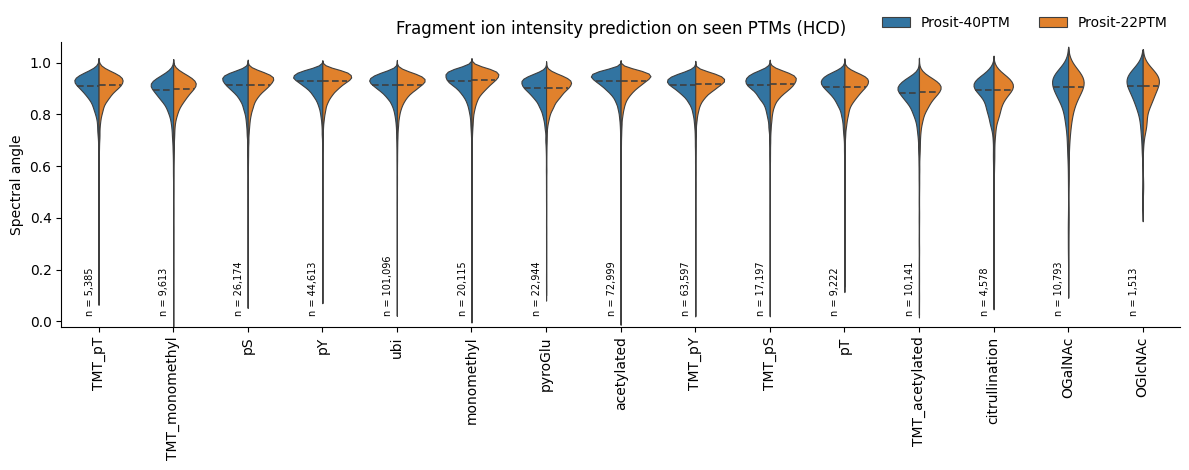

,x_label,raw_file_package,n_spectra_Prosit-40PTM,n_spectra_Prosit-22PTM,n_label,median_SA_Prosit-40PTM,median_SA_Prosit-22PTM
0,TMT_pT,TMT_TUM_mod_pT,5385,5385,5385,0.911711,0.913365
1,TMT_monomethyl,TMT_TUM_mod_monomethyl,9613,9613,9613,0.895292,0.900369
2,pS,TUM_mod_pS,26174,26174,26174,0.915624,0.915509
3,pY,TUM_mod_pY,44613,44613,44613,0.928235,0.928687
4,ubi,TUM_mod_ubi,101096,101096,101096,0.915485,0.915811
5,monomethyl,TUM_mod_monomethyl,20115,20115,20115,0.929902,0.932309
6,pyroGlu,TUM_mod_pyroGlu,22944,22944,22944,0.903048,0.902589
7,acetylated,TUM_mod_acetylated,72999,72999,72999,0.928579,0.929468
8,TMT_pY,TMT_TUM_mod_pY,63597,63597,63597,0.914064,0.917889
9,TMT_pS,TMT_TUM_mod_pS,17197,17197,17197,0.912923,0.918053


In [4]:
b_sum = table('ED_Fig6b_summary')
b = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig6b.parquet'))
order = b_sum['x_label'].tolist()
long = b[['x_label', 'model', 'spectral_angle']].rename(columns={'x_label': 'group'})
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.violinplot(data=long, x='group', y='spectral_angle', hue='model', order=order,
               hue_order=['Prosit-40PTM', 'Prosit-22PTM'], split=True, inner='quart',
               palette={'Prosit-40PTM': '#1f77b4', 'Prosit-22PTM': '#ff7f0e'}, linewidth=0.8, ax=ax)
median_only(ax, long, 'group', 'spectral_angle', 'model', order, ['Prosit-40PTM', 'Prosit-22PTM'])
for i, r in b_sum.iterrows():
    ax.text(i - 0.12, 0.02, 'n = {:,}'.format(r['n_label']), rotation=90, fontsize=7,
            ha='center', va='bottom')
ax.set_xlabel('')
ax.set_ylabel('Spectral angle')
ax.set_ylim(-0.02, 1.08)
ax.tick_params(axis='x', rotation=90)
ax.set_title('Fragment ion intensity prediction on seen PTMs (HCD)')
ax.legend(title=None, frameon=False, loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=2)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
save('ED_Fig6b')
plt.show()
b_sum

## Panel c — Prosit-40PTM vs Prosit-22PTM on PTMs unseen by Prosit-22PTM
HCD spectra of the 15 ProteomeTools PTM training-kit modifications not in the Prosit-22PTM training data; both models on
the same spectra (Prosit-40PTM left, Prosit-22PTM right). n = spectra per PTM.

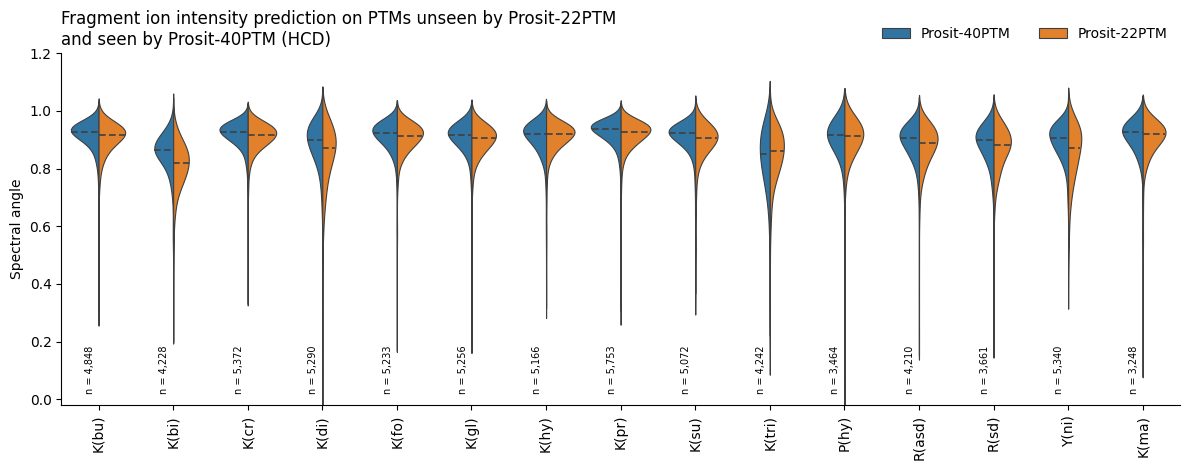

,x_label,package,"n_spectra (both models, HCD)",median_SA_Prosit-40PTM,median_SA_Prosit-22PTM
0,K(bu),Kmod_Butyryl,4848,0.928007,0.917462
1,K(bi),Kmod_Biotin,4228,0.865097,0.817843
2,K(cr),Kmod_Crotonyl,5372,0.927531,0.916217
3,K(di),Kmod_Dimethyl,5290,0.900382,0.869917
4,K(fo),Kmod_Formyl,5233,0.923154,0.914515
5,K(gl),Kmod_Glutaryl,5256,0.917712,0.905998
6,K(hy),Kmod_Hydroxyisobut,5166,0.921427,0.919299
7,K(pr),Kmod_Propion,5753,0.936401,0.926366
8,K(su),Kmod_Succinyl,5072,0.921553,0.904770
9,K(tri),Kmod_Trimethyl,4242,0.849832,0.860985


In [5]:
c_sum = table('ED_Fig6c_summary')
c = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig6c.parquet'))
order = c_sum['x_label'].tolist()
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.violinplot(data=c, x='x_label', y='spectral_angle', hue='model', order=order,
               hue_order=['Prosit-40PTM', 'Prosit-22PTM'], split=True, inner='quart', bw_adjust=2.5,
               palette={'Prosit-40PTM': '#1f77b4', 'Prosit-22PTM': '#ff7f0e'}, linewidth=0.8, ax=ax)
median_only(ax, c, 'x_label', 'spectral_angle', 'model', order, ['Prosit-40PTM', 'Prosit-22PTM'])
for i, r in c_sum.iterrows():
    ax.text(i - 0.12, 0.02, 'n = {:,}'.format(r['n_spectra (both models, HCD)']), rotation=90, fontsize=7,
            ha='center', va='bottom')
ax.set_xlabel('')
ax.set_ylabel('Spectral angle')
ax.set_ylim(-0.02, 1.2)
ax.tick_params(axis='x', rotation=90)
ax.set_title('Fragment ion intensity prediction on PTMs unseen by Prosit-22PTM\nand seen by Prosit-40PTM (HCD)', loc='left')
ax.legend(title=None, frameon=False, loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=2)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
save('ED_Fig6c')
plt.show()
c_sum